# EDA: 2020 COVID-19 Market Crash — S&P 500 index-only edition

**Data source:** `sp500_historical_data.csv` in the RGBFS repository root. This notebook is adapted from `eda_2020.ipynb` to work without the missing constituent-level Parquet files.

**Scope:** Index price, returns, drawdowns, volatility, volume and event timing. **Not supported by this CSV:** historical constituent membership, coverage, stock-level breadth, cross-sectional dispersion, equal-weighted member returns, or stock connectedness. The original notebook's conclusions for those metrics must not be carried over as results of this run.

**Important:** The original notebook identifies `scripts/download_sp500_prices.py` as the intended producer of the full constituent dataset. Run that script if you need the original stock-level analysis.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
CSV = ROOT / "sp500_historical_data.csv"
START, END = "2020-01-01", "2020-12-31"
BASE0, BASE1 = "2019-04-01", "2019-12-31"
EVENTS = {
    "2020-01-30": "WHO emergency",
    "2020-02-19": "S&P peak",
    "2020-03-09": "Mar 9 fall",
    "2020-03-16": "Mar 16 fall",
    "2020-03-23": "S&P low, Fed",
    "2020-08-18": "Record regained",
    "2020-11-09": "Vaccine news",
}

def mark_events(ax, labels=False):
    for day, label in EVENTS.items():
        ax.axvline(pd.Timestamp(day), color="grey", ls="--", lw=0.8)
        if labels:
            ax.text(pd.Timestamp(day), 1.01, label,
                    transform=ax.get_xaxis_transform(), rotation=90,
                    va="bottom", ha="center", fontsize=8, color="dimgrey")

print("CSV:", CSV)
print("Exists:", CSV.is_file())


CSV: C:\Users\dayan\Downloads\RGBFS\sp500_historical_data.csv
Exists: True


## 1. Load and validate the CSV

In [2]:
if not CSV.is_file():
    raise FileNotFoundError(f"Cannot find {CSV}. Put the CSV in the RGBFS root or change CSV above.")

# Yahoo/yfinance multi-row CSV: header row followed by Ticker and Date rows.
# Read the first few lines to detect this format rather than blindly dropping data.
with CSV.open("r", encoding="utf-8-sig") as f:
    first_three = [f.readline().strip() for _ in range(3)]
print("CSV header preview:", first_three)

has_yahoo_headers = (first_three[1].split(",")[0].strip('"') == "Ticker"
                     and first_three[2].split(",")[0].strip('"') == "Date")
raw = pd.read_csv(CSV, skiprows=[1, 2] if has_yahoo_headers else None)
raw.columns = raw.columns.str.strip()
if "Price" in raw.columns and "Date" not in raw.columns:
    raw = raw.rename(columns={"Price": "Date"})
if "Date" not in raw.columns or "Close" not in raw.columns:
    raise ValueError(f"Expected Date and Close columns; found {raw.columns.tolist()}")
raw["Date"] = pd.to_datetime(raw["Date"], errors="coerce")
for col in ("Close", "High", "Low", "Open", "Volume"):
    if col in raw.columns:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")
raw = raw.dropna(subset=["Date", "Close"])
close = raw.set_index("Date").sort_index()
close = close.loc[~close.index.duplicated(keep="last")]
close = close.loc[:END]
gspc = close["Close"]
if gspc.loc[START:END].empty:
    raise ValueError("The CSV has no S&P 500 closing prices in 2020.")
print("Dates:", close.index.min().date(), "to", close.index.max().date())
print("Rows:", len(close), "Columns:", close.columns.tolist())
display(close.loc[START:END].head())


CSV header preview: ['Price,Close,High,Low,Open,Volume', 'Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC', 'Date,,,,,']
Dates: 1927-12-26 to 2020-12-28
Rows: 4853 Columns: ['Close', 'High', 'Low', 'Open', 'Volume']


,Close,High,Low,Open,Volume
Date,,,,,
2020-01-06,3265.350098,3282.989990,3214.639893,3217.550049,17721020000
2020-01-13,3329.620117,3329.879883,3268.429932,3271.129883,18135300000
2020-01-20,3295.469971,3337.770020,3281.530029,3321.030029,15204110000
2020-01-27,3225.520020,3293.469971,3214.679932,3247.159912,19282920000
2020-02-03,3327.709961,3347.959961,3235.659912,3235.659912,19500010000


## 2. Data quality — index only

This checks date duplicates, missing index values and available volume. It does **not** measure constituent coverage or survivorship bias.

In [3]:
quality = pd.Series({
    "rows_in_loaded_period": len(close),
    "missing_close": int(close["Close"].isna().sum()),
    "duplicate_dates_after_cleaning": int(close.index.duplicated().sum()),
    "2020_trading_days": len(close.loc[START:END]),
})
display(quality.to_frame("value"))


,value
rows_in_loaded_period,4853
missing_close,0
duplicate_dates_after_cleaning,0
2020_trading_days,52


## 3. Market overview — level, drawdown, daily returns and volatility

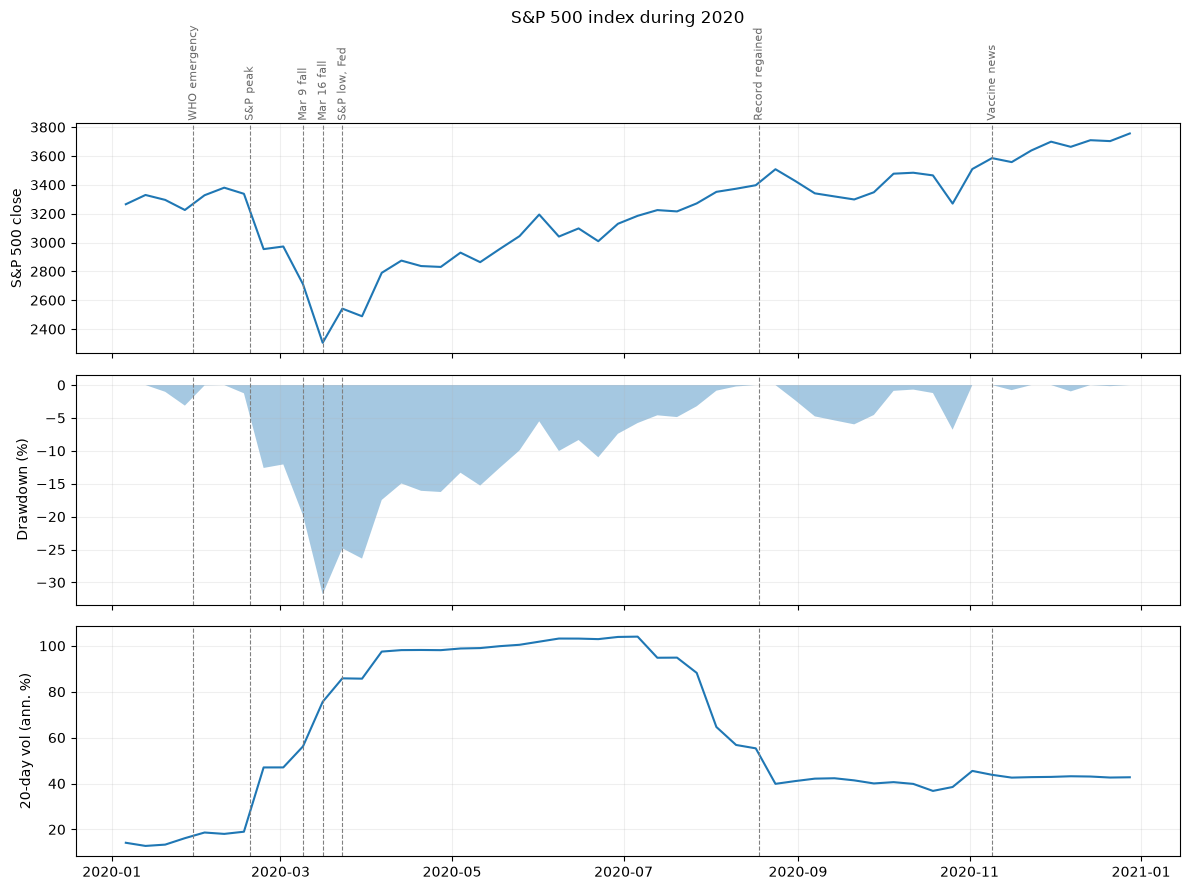

Pre-trough peak: 2020-02-10 at 3,380.16
2020 trough: 2020-03-16 at 2,304.92
Peak-to-trough decline: -31.8%
Previous peak regained: 2020-08-17
Highest 20-day annualized volatility: 104.0%
Worst 3 days: [(datetime.date(2020, 3, 16), '-15.0%'), (datetime.date(2020, 2, 24), '-11.5%'), (datetime.date(2020, 3, 9), '-8.8%')]
Best 3 days: [(datetime.date(2020, 4, 6), '+12.1%'), (datetime.date(2020, 3, 23), '+10.3%'), (datetime.date(2020, 11, 2), '+7.3%')]


In [4]:
g = gspc.loc[START:END]
daily_idx = gspc.pct_change(fill_method=None)
# Drawdown from running peak, including the 2019 run-up so the February 2020 peak is correctly referenced.
prior = gspc.loc[:END]
drawdown = (prior / prior.cummax() - 1).loc[START:END]
vol20 = (daily_idx.rolling(20, min_periods=20).std() * np.sqrt(252)).loc[START:END]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(g.index, g)
axes[0].set_ylabel("S&P 500 close")
axes[1].fill_between(drawdown.index, drawdown * 100, 0, alpha=0.4)
axes[1].set_ylabel("Drawdown (%)")
axes[2].plot(vol20.index, vol20 * 100)
axes[2].set_ylabel("20-day vol (ann. %)")
for i, ax in enumerate(axes):
    mark_events(ax, labels=(i == 0))
    ax.grid(alpha=0.2)
axes[0].set_title("S&P 500 index during 2020", pad=72)
plt.tight_layout()
plt.show()

trough_date = g.idxmin()
peak_date = g.loc[:trough_date].idxmax()
regained = g.loc[trough_date:]
regained = regained[regained >= g.loc[peak_date]]
d = daily_idx.loc[START:END].dropna()
print(f"Pre-trough peak: {peak_date.date()} at {g.loc[peak_date]:,.2f}")
print(f"2020 trough: {trough_date.date()} at {g.loc[trough_date]:,.2f}")
print(f"Peak-to-trough decline: {g.loc[trough_date] / g.loc[peak_date] - 1:.1%}")
print("Previous peak regained:", regained.index[0].date() if len(regained) else "Not within 2020")
print("Highest 20-day annualized volatility:", f"{vol20.max():.1%}")
print("Worst 3 days:", [(x.date(), f"{v:.1%}") for x, v in d.nsmallest(3).items()])
print("Best 3 days:", [(x.date(), f"{v:+.1%}") for x, v in d.nlargest(3).items()])


## 4. Returns and trading volume

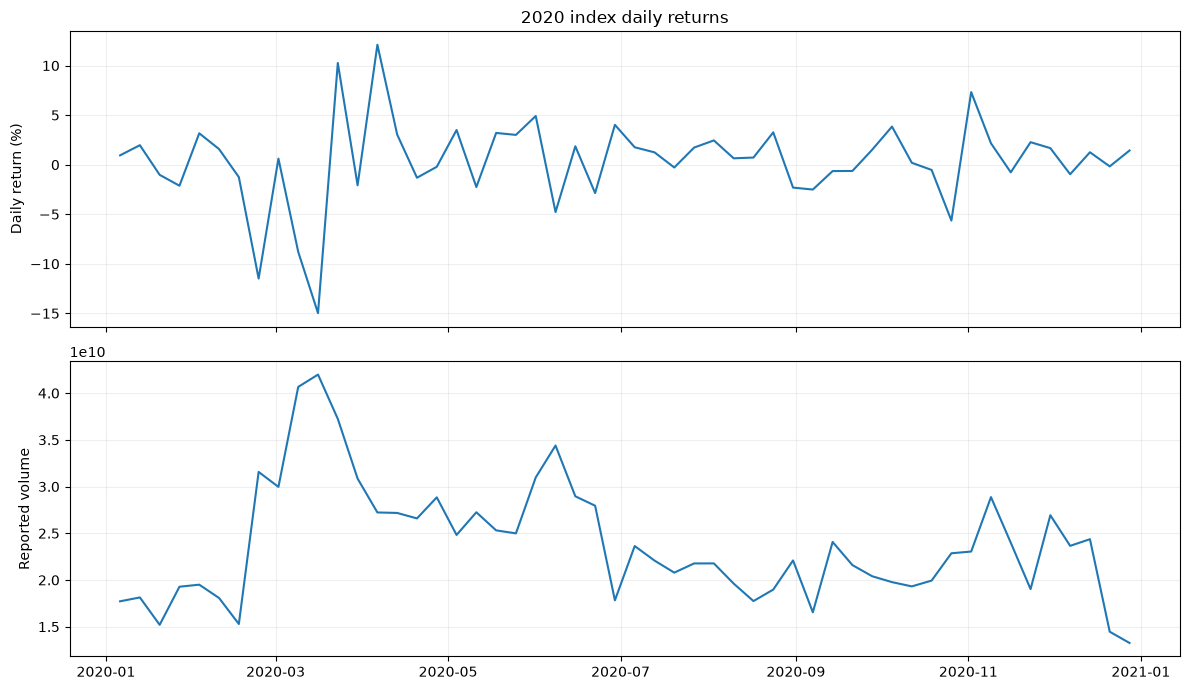

In [5]:
fig, axes = plt.subplots(2 if "Volume" in close.columns else 1, 1,
                         figsize=(12, 7), sharex=True)
if not isinstance(axes, np.ndarray):
    axes = [axes]
axes[0].plot(d.index, d * 100)
axes[0].set_ylabel("Daily return (%)")
axes[0].set_title("2020 index daily returns")
axes[0].grid(alpha=0.2)
if "Volume" in close.columns:
    axes[1].plot(close.loc[START:END].index, close.loc[START:END, "Volume"])
    axes[1].set_ylabel("Reported volume")
    axes[1].grid(alpha=0.2)
    if close.loc[START:END, "Volume"].fillna(0).eq(0).all():
        print("Note: volume is entirely zero or missing in 2020; do not interpret the volume plot.")
plt.tight_layout()
plt.show()


## 5. Timing of unusual index volatility

Illustrative threshold: 2019-04-01 to 2019-12-31 mean plus two standard deviations of 20-day annualized volatility. This is a descriptive threshold, not a validated predictive model.

2019 baseline threshold: 40.7%
First 2020 crossing: 2020-02-24


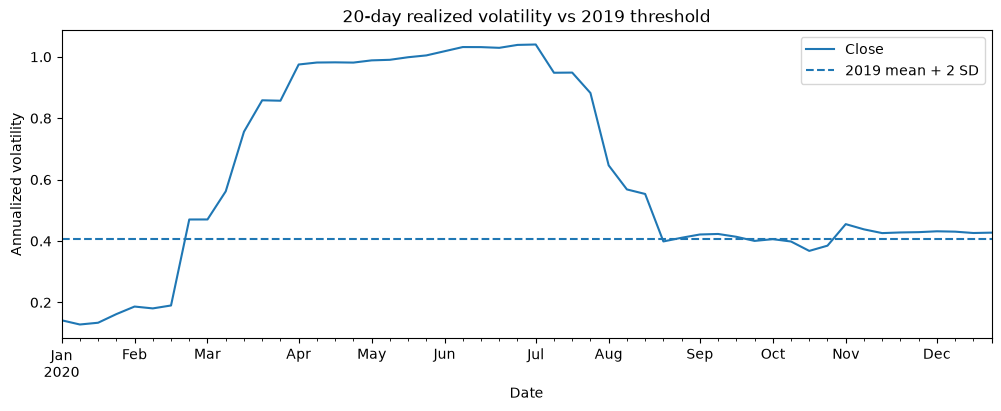

In [6]:
full_vol20 = daily_idx.rolling(20, min_periods=20).std() * np.sqrt(252)
baseline = full_vol20.loc[BASE0:BASE1].dropna()
if len(baseline) < 20:
    print("Not enough 2019 baseline data for a threshold.")
else:
    threshold = baseline.mean() + 2 * baseline.std()
    crossed = full_vol20.loc[START:END]
    crossed = crossed[crossed > threshold]
    print("2019 baseline threshold:", f"{threshold:.1%}")
    print("First 2020 crossing:", crossed.index[0].date() if len(crossed) else "None")
    ax = full_vol20.loc[START:END].plot(figsize=(12, 4), title="20-day realized volatility vs 2019 threshold")
    ax.axhline(threshold, linestyle="--", label="2019 mean + 2 SD")
    ax.legend()
    ax.set_ylabel("Annualized volatility")
    plt.show()


## 6. Save index-level outputs

Output names explicitly say `index` to avoid confusion with the original notebook’s stock-level files.

In [7]:
out = ROOT / "data" / "processed" / "eda_2020_index_only"
out.mkdir(parents=True, exist_ok=True)
close.loc[START:END].to_csv(out / "sp500_index_2020.csv")
d.rename("daily_return").to_csv(out / "sp500_index_daily_returns_2020.csv")
vol20.rename("annualized_volatility_20d").to_csv(out / "sp500_index_volatility_2020.csv")
print("Saved outputs to:", out)


Saved outputs to: C:\Users\dayan\Downloads\RGBFS\data\processed\eda_2020_index_only
